# 🏦 Bank Customer Churn Prediction: Kaggle S4E1


**Objective:** Predict whether a customer continues with their bank or closes their account (churns).
**Pipeline Overview:**
1. Setup & Data Loading
2. Feature Engineering, PCA & KMeans Clustering
3. Preprocessing (StandardScaler, One-Hot Encoding)
4. XGBoost Baseline
5. Hyperparameter Tuning with Optuna (XGBoost, LightGBM, CatBoost)
6. Model Stacking
7. Model Interpretation with SHAP

## 0. Install libraries

In [1]:
# In Kaggle notebooks many of these packages may already be installed.
# In Google Colab, run this cell once if required.
%pip install -q optuna shap catboost lightgbm xgboost scikit-learn

In [2]:
import os
import random
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    log_loss,
    precision_score,
    recall_score,
    roc_auc_score,
    RocCurveDisplay,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.cluster import KMeans

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
import optuna
import shap

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
optuna.logging.set_verbosity(optuna.logging.WARNING)

print("Imports complete")

Imports complete


## 1. Load the competition files

This loader supports either the Kaggle input directory or the Google Drive ZIP workflow used in the original draft. If you use Colab, update the ZIP path if your file is stored somewhere else. The ZIP must contain `train.csv` and `test.csv`, possibly inside a subfolder.

In [3]:
KAGGLE_DIR = Path("/kaggle/input/playground-series-s4e1")
DRIVE_ZIP_PATH = Path("/content/drive/My Drive/Classification-bank_Churn.zip")
EXTRACT_DIR = Path("/content/Classification-bank_Churn_extracted")

if (KAGGLE_DIR / "train.csv").exists() and (KAGGLE_DIR / "test.csv").exists():
    train_path = KAGGLE_DIR / "train.csv"
    test_path = KAGGLE_DIR / "test.csv"
    print("Using Kaggle input directory:", KAGGLE_DIR)
else:
    # This path is intended for Google Colab. Mount Drive only when needed.
    try:
        from google.colab import drive
    except ImportError as exc:
        raise FileNotFoundError(
            "Could not find Kaggle input files. Run in Colab and set DRIVE_ZIP_PATH, "
            "or update KAGGLE_DIR to your dataset folder."
        ) from exc

    drive.mount("/content/drive")
    if not DRIVE_ZIP_PATH.exists():
        raise FileNotFoundError(
            f"ZIP not found: {DRIVE_ZIP_PATH}\n"
            "Update DRIVE_ZIP_PATH to the location of Classification-bank_Churn.zip in Drive."
        )

    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(DRIVE_ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(EXTRACT_DIR)

    pairs = [p for p in EXTRACT_DIR.rglob("train.csv") if (p.parent / "test.csv").exists()]
    if not pairs:
        raise FileNotFoundError(
            f"Could not find train.csv and test.csv together under {EXTRACT_DIR}. "
            "Check the contents of your ZIP."
        )
    train_path = pairs[0]
    test_path = train_path.parent / "test.csv"
    print("Using extracted files:", train_path.parent)

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

TARGET = "Exited"
if TARGET not in train_df.columns:
    raise ValueError(f"Expected target column '{TARGET}' in train.csv")
if "id" not in test_df.columns:
    raise ValueError("Expected 'id' column in test.csv for the Kaggle submission")

test_ids = test_df["id"].copy()
print(f"Train shape: {train_df.shape}")
print(f"Test shape:  {test_df.shape}")
print("Train columns:", train_df.columns.tolist())
print("Test columns:", test_df.columns.tolist())
display(train_df.head())

Mounted at /content/drive
Using extracted files: /content/Classification-bank_Churn_extracted
Train shape: (165034, 14)
Test shape:  (110023, 13)
Train columns: ['id', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']
Test columns: ['id', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']


,id,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,0,15674932,Okwudilichukwu,668,France,Male,33.0,3,0.00,2,1.0,0.0,181449.97,0
1,1,15749177,Okwudiliolisa,627,France,Male,33.0,1,0.00,2,1.0,1.0,49503.50,0
2,2,15694510,Hsueh,678,France,Male,40.0,10,0.00,2,1.0,0.0,184866.69,0
3,3,15741417,Kao,581,France,Male,34.0,2,148882.54,1,1.0,1.0,84560.88,0
4,4,15766172,Chiemenam,716,Spain,Male,33.0,5,0.00,2,1.0,1.0,15068.83,0


## 2. Exploratory data analysis (EDA)

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 165034 entries, 0 to 165033
Data columns (total 14 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   id               165034 non-null  int64  
 1   CustomerId       165034 non-null  int64  
 2   Surname          165034 non-null  object 
 3   CreditScore      165034 non-null  int64  
 4   Geography        165034 non-null  object 
 5   Gender           165034 non-null  object 
 6   Age              165034 non-null  float64
 7   Tenure           165034 non-null  int64  
 8   Balance          165034 non-null  float64
 9   NumOfProducts    165034 non-null  int64  
 10  HasCrCard        165034 non-null  float64
 11  IsActiveMember   165034 non-null  float64
 12  EstimatedSalary  165034 non-null  float64
 13  Exited           165034 non-null  int64  
dtypes: float64(5), int64(6), object(3)
memory usage: 17.6+ MB

Missing values in train (top 20):


,missing_count
id,0
CustomerId,0
Surname,0
CreditScore,0
Geography,0
Gender,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0



Duplicate full rows: 0

Target counts:


,count
Exited,
0,130113
1,34921



Target percentages:


,percent
Exited,
0,78.84
1,21.16


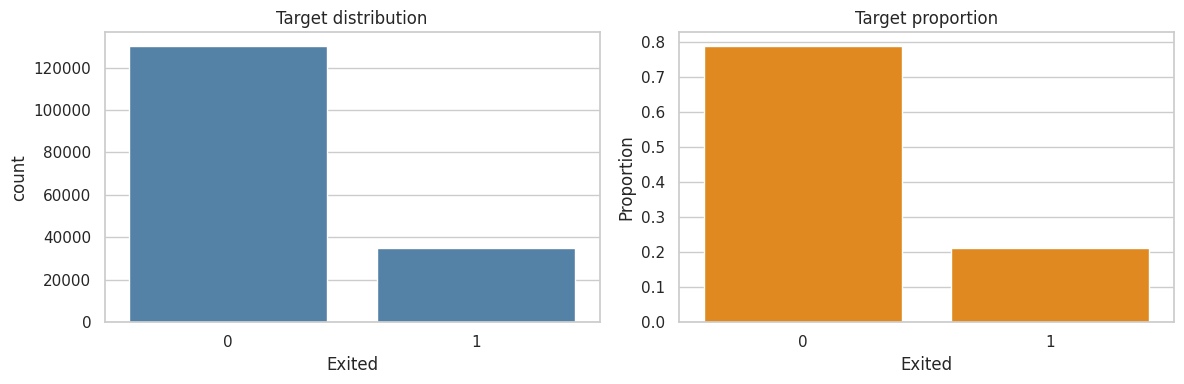

In [4]:
print("Data types and non-null counts:")
train_df.info()

print("\nMissing values in train (top 20):")
display(train_df.isna().sum().sort_values(ascending=False).head(20).to_frame("missing_count"))

print("\nDuplicate full rows:", train_df.duplicated().sum())
print("\nTarget counts:")
display(train_df[TARGET].value_counts().sort_index().to_frame("count"))
print("\nTarget percentages:")
display((train_df[TARGET].value_counts(normalize=True).sort_index() * 100).round(2).to_frame("percent"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=train_df, x=TARGET, ax=axes[0], color="steelblue")
axes[0].set_title("Target distribution")
sns.barplot(x=train_df[TARGET].value_counts(normalize=True).sort_index().index,
            y=train_df[TARGET].value_counts(normalize=True).sort_index().values,
            ax=axes[1], color="darkorange")
axes[1].set_title("Target proportion")
axes[1].set_ylabel("Proportion")
plt.tight_layout()
plt.show()

In [5]:
# Churn rates for a few useful categories. This is descriptive EDA, not feature selection by itself.
for col in ["Geography", "Gender", "NumOfProducts", "IsActiveMember", "HasCrCard"]:
    if col in train_df.columns:
        churn_rate = train_df.groupby(col, dropna=False)[TARGET].mean().sort_values(ascending=False)
        print(f"\nMean churn rate by {col}:")
        display(churn_rate.rename("churn_rate").to_frame())

numeric_cols_original = train_df.select_dtypes(include=np.number).columns.tolist()
numeric_cols_original = [c for c in numeric_cols_original if c not in [TARGET, "id", "CustomerId", "RowNumber"]]
if numeric_cols_original:
    display(train_df[numeric_cols_original].describe().T)


Mean churn rate by Geography:


,churn_rate
Geography,
Germany,0.378952
Spain,0.172176
France,0.165282



Mean churn rate by Gender:


,churn_rate
Gender,
Female,0.279687
Male,0.159055



Mean churn rate by NumOfProducts:


...


Mean churn rate by IsActiveMember:


,churn_rate
IsActiveMember,
0.0,0.297086
1.0,0.125345



Mean churn rate by HasCrCard:


,churn_rate
HasCrCard,
0.0,0.227429
1.0,0.206433


,count,mean,std,min,25%,50%,75%,max
CreditScore,165034.0,656.454373,80.103340,350.00,597.00,659.0,710.0000,850.00
Age,165034.0,38.125888,8.867205,18.00,32.00,37.0,42.0000,92.00
Tenure,165034.0,5.020353,2.806159,0.00,3.00,5.0,7.0000,10.00
Balance,165034.0,55478.086689,62817.663278,0.00,0.00,0.0,119939.5175,250898.09
NumOfProducts,165034.0,1.554455,0.547154,1.00,1.00,2.0,2.0000,4.00
HasCrCard,165034.0,0.753954,0.430707,0.00,1.00,1.0,1.0000,1.00
IsActiveMember,165034.0,0.497770,0.499997,0.00,0.00,0.0,1.0000,1.00
EstimatedSalary,165034.0,112574.822734,50292.865585,11.58,74637.57,117948.0,155152.4675,199992.48


## 3. Feature engineering

We remove row/customer identifiers from the default model inputs to reduce the risk of learning arbitrary IDs. The feature engineering below adds a few interpretable ratios, interactions, and grouped categorical features. Tree models do not require standard scaling, so numeric features are passed through for XGBoost / LightGBM. A separate standardized preprocessing pipeline is used for the logistic-regression baseline and the PCA experiment.

The transformations are deterministic and do not use `Exited`. Preprocessors, PCA, and KMeans are fit only on the training split, then applied to validation/test data.

In [6]:
ID_COLUMNS = ["id", "CustomerId", "Surname", "RowNumber"]


def engineer_features(frame: pd.DataFrame) -> pd.DataFrame:
    """Create deterministic, target-independent features from raw competition columns."""
    df = frame.copy()
    df = df.drop(columns=[c for c in ID_COLUMNS if c in df.columns], errors="ignore")

    # Convert known numeric columns safely; tree models can handle numeric NaNs.
    numeric_candidates = [
        "CreditScore", "Age", "Tenure", "Balance", "NumOfProducts",
        "HasCrCard", "IsActiveMember", "EstimatedSalary"
    ]
    for col in numeric_candidates:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")

    # Keep categorical values stable, including unexpected/missing values.
    for col in ["Geography", "Gender"]:
        if col in df.columns:
            df[col] = df[col].fillna("Unknown").astype(str)

    # Ratios/interactions. Small constants avoid division by zero.
    if {"Balance", "EstimatedSalary"}.issubset(df.columns):
        df["BalanceSalaryRatio"] = df["Balance"] / (df["EstimatedSalary"].abs() + 1.0)
        df["ZeroBalance"] = (df["Balance"].fillna(0) == 0).astype(int)
    if {"Balance", "CreditScore"}.issubset(df.columns):
        df["BalanceCreditScoreRatio"] = df["Balance"] / (df["CreditScore"].abs() + 1.0)
    if {"Tenure", "Age"}.issubset(df.columns):
        df["TenureAgeRatio"] = df["Tenure"] / (df["Age"].abs() + 1.0)
    if {"Age", "NumOfProducts"}.issubset(df.columns):
        df["AgeTimesProducts"] = df["Age"] * df["NumOfProducts"]
    if {"CreditScore", "Age"}.issubset(df.columns):
        df["CreditScorePerAge"] = df["CreditScore"] / (df["Age"].abs() + 1.0)

    if "Age" in df.columns:
        df["AgeGroup"] = pd.cut(
            df["Age"],
            bins=[0, 25, 35, 45, 55, 65, 120],
            labels=["18-25", "26-35", "36-45", "46-55", "56-65", "66+"],
            include_lowest=True,
        ).astype("object").fillna("Unknown")
    if "Tenure" in df.columns:
        df["TenureGroup"] = pd.cut(
            df["Tenure"],
            bins=[-1, 0, 2, 5, 8, 10, 100],
            labels=["0", "1-2", "3-5", "6-8", "9-10", "11+"],
            include_lowest=True,
        ).astype("object").fillna("Unknown")
    if "CreditScore" in df.columns:
        df["CreditScoreBand"] = pd.cut(
            df["CreditScore"],
            bins=[-np.inf, 500, 600, 700, 800, np.inf],
            labels=["very_low", "low", "medium", "high", "very_high"],
        ).astype("object").fillna("Unknown")
    if "NumOfProducts" in df.columns:
        df["NumOfProductsCat"] = df["NumOfProducts"].round().astype("Int64").astype(str)

    # Convert categorical columns to strings so CatBoost sees consistent category values.
    for col in df.select_dtypes(include=["object", "category"]).columns:
        df[col] = df[col].fillna("Unknown").astype(str)

    return df

X_all_raw = engineer_features(train_df.drop(columns=[TARGET]))
y_all = train_df[TARGET].astype(int).reset_index(drop=True)
X_test_raw = engineer_features(test_df)
X_test_raw = X_test_raw.reindex(columns=X_all_raw.columns)

X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_all_raw,
    y_all,
    test_size=0.20,
    random_state=SEED,
    stratify=y_all,
)

# Reset row indices for safer concatenation during cross-validation / stacking.
X_train_raw = X_train_raw.reset_index(drop=True)
X_val_raw = X_val_raw.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_val = y_val.reset_index(drop=True)
X_all_raw = X_all_raw.reset_index(drop=True)
X_test_raw = X_test_raw.reset_index(drop=True)

CAT_COLS = X_train_raw.select_dtypes(include=["object", "category"]).columns.tolist()
NUM_COLS = [c for c in X_train_raw.columns if c not in CAT_COLS]

print("Feature matrix shape:", X_all_raw.shape)
print("Categorical features:", CAT_COLS)
print("Numeric features:", NUM_COLS)
display(X_train_raw.head())

Feature matrix shape: (165034, 20)
Categorical features: ['Geography', 'Gender', 'AgeGroup', 'TenureGroup', 'CreditScoreBand', 'NumOfProductsCat']
Numeric features: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'BalanceSalaryRatio', 'ZeroBalance', 'BalanceCreditScoreRatio', 'TenureAgeRatio', 'AgeTimesProducts', 'CreditScorePerAge']


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,BalanceSalaryRatio,ZeroBalance,BalanceCreditScoreRatio,TenureAgeRatio,AgeTimesProducts,CreditScorePerAge,AgeGroup,TenureGroup,CreditScoreBand,NumOfProductsCat
0,726,France,Female,35.0,1,0.00,2,1.0,1.0,141466.85,0.000000,1,0.000000,0.027778,70.0,20.166667,26-35,1-2,high,2
1,481,France,Female,37.0,8,152303.66,2,1.0,0.0,175082.20,0.869893,0,315.982697,0.210526,74.0,12.657895,36-45,6-8,very_low,2
2,583,France,Female,35.0,5,0.00,1,0.0,0.0,102581.11,0.000000,1,0.000000,0.138889,35.0,16.194444,26-35,3-5,low,1
3,644,France,Female,32.0,7,0.00,2,1.0,0.0,77965.67,0.000000,1,0.000000,0.212121,64.0,19.515152,26-35,6-8,medium,2
4,709,France,Male,29.0,5,128548.49,1,1.0,1.0,140941.47,0.912064,0,181.054211,0.166667,29.0,23.633333,26-35,3-5,high,1


### Optional: use the original Bank Customer Churn dataset as extra training rows

The competition data is synthetic. Some public solutions experiment with the smaller original bank-churn dataset as extra training data. This is optional: download the [source Bank Customer Churn dataset](https://www.kaggle.com/datasets/shubhammeshram579/bank-customer-churn-prediction) from Kaggle, save its CSV in Drive, and set `USE_ORIGINAL_DATA = True`. Keep your validation split drawn only from the competition training file so the validation score represents the competition distribution. Compare the validation results with and without augmentation; additional data is not guaranteed to improve the score.

In [7]:
USE_ORIGINAL_DATA = False
ORIGINAL_DATA_PATH = Path("/content/drive/My Drive/Churn_Modelling.csv")

X_extra_raw = None
y_extra = None
if USE_ORIGINAL_DATA:
    if not ORIGINAL_DATA_PATH.exists():
        raise FileNotFoundError(
            f"Original dataset not found at {ORIGINAL_DATA_PATH}. "
            "Update ORIGINAL_DATA_PATH or set USE_ORIGINAL_DATA = False."
        )
    original_df = pd.read_csv(ORIGINAL_DATA_PATH)
    if TARGET not in original_df.columns:
        raise ValueError(f"Original CSV must contain '{TARGET}'")
    y_extra = original_df[TARGET].astype(int).reset_index(drop=True)
    X_extra_raw = engineer_features(original_df.drop(columns=[TARGET]))
    X_extra_raw = X_extra_raw.reindex(columns=X_train_raw.columns)
    print("External source rows enabled:", X_extra_raw.shape[0])
else:
    print("External source rows disabled; only competition train.csv is used.")


def combine_with_extra(X_part, y_part, X_extra=X_extra_raw, y_extra_values=y_extra):
    """Append optional external source rows to a model-fitting partition only."""
    X_part = X_part.reset_index(drop=True)
    y_part = pd.Series(y_part).reset_index(drop=True)
    if X_extra is None or y_extra_values is None:
        return X_part, y_part
    X_combined = pd.concat([X_part, X_extra.reset_index(drop=True)], ignore_index=True)
    y_combined = pd.concat([y_part, pd.Series(y_extra_values).reset_index(drop=True)], ignore_index=True)
    return X_combined, y_combined

X_fit_rows, y_fit_rows = combine_with_extra(X_train_raw, y_train)
print("Rows available for fitting (including optional source rows):", len(X_fit_rows))

External source rows disabled; only competition train.csv is used.
Rows available for fitting (including optional source rows): 132027


## 4. Baselines and preprocessing

A baseline provides a reference point before running expensive optimization. We report ROC-AUC, accuracy at a 0.50 threshold, precision, recall, F1, and log loss. For this competition, ROC-AUC is the primary metric.

,model,ROC-AUC,accuracy@0.50,precision@0.50,recall@0.50,F1@0.50,log_loss
2,XGBoost baseline,0.88945,0.86527,0.74371,0.55427,0.63516,0.31952
1,Logistic regression,0.87701,0.86200,0.74305,0.53164,0.61981,0.33335
0,Dummy / prior,0.50000,0.78841,0.00000,0.00000,0.00000,0.51606


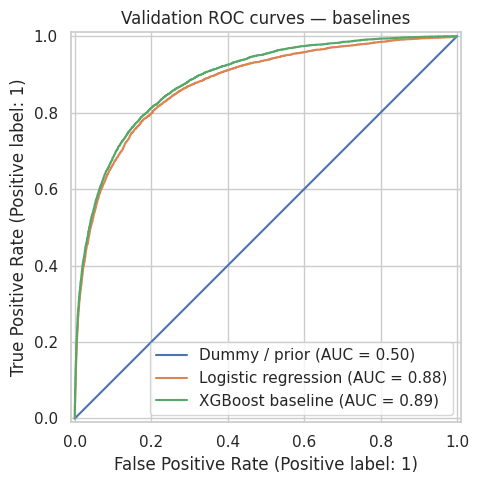

In [8]:
def make_one_hot_encoder():
    """Support recent and older scikit-learn OneHotEncoder parameter names."""
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)


def make_tree_preprocessor():
    cat_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", make_one_hot_encoder()),
    ])
    num_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
    ])
    return ColumnTransformer(
        transformers=[("cat", cat_pipe, CAT_COLS), ("num", num_pipe, NUM_COLS)],
        remainder="drop",
        sparse_threshold=0,
        verbose_feature_names_out=True,
    )


def make_linear_pipeline():
    cat_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", make_one_hot_encoder()),
    ])
    num_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    prep = ColumnTransformer(
        transformers=[("cat", cat_pipe, CAT_COLS), ("num", num_pipe, NUM_COLS)],
        remainder="drop",
        sparse_threshold=0,
    )
    return Pipeline([
        ("preprocessor", prep),
        ("model", LogisticRegression(max_iter=2000, random_state=SEED)),
    ])


def metric_row(name, y_true, probabilities):
    probabilities = np.asarray(probabilities).reshape(-1)
    predictions = (probabilities >= 0.50).astype(int)
    return {
        "model": name,
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "accuracy@0.50": accuracy_score(y_true, predictions),
        "precision@0.50": precision_score(y_true, predictions, zero_division=0),
        "recall@0.50": recall_score(y_true, predictions, zero_division=0),
        "F1@0.50": f1_score(y_true, predictions, zero_division=0),
        "log_loss": log_loss(y_true, np.clip(probabilities, 1e-7, 1 - 1e-7)),
    }

baseline_rows = []

dummy = DummyClassifier(strategy="prior")
dummy.fit(np.zeros((len(y_train), 1)), y_train)
dummy_probs = dummy.predict_proba(np.zeros((len(y_val), 1)))[:, 1]
baseline_rows.append(metric_row("Dummy / prior", y_val, dummy_probs))

logreg = make_linear_pipeline()
X_log_fit, y_log_fit = combine_with_extra(X_train_raw, y_train)
logreg.fit(X_log_fit, y_log_fit)
logreg_probs = logreg.predict_proba(X_val_raw)[:, 1]
baseline_rows.append(metric_row("Logistic regression", y_val, logreg_probs))

xgb_baseline = Pipeline([
    ("preprocessor", make_tree_preprocessor()),
    ("model", XGBClassifier(
        objective="binary:logistic",
        eval_metric="auc",
        tree_method="hist",
        n_estimators=500,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.85,
        colsample_bytree=0.85,
        min_child_weight=3,
        reg_lambda=2.0,
        n_jobs=-1,
        random_state=SEED,
    )),
])
xgb_baseline.fit(X_fit_rows, y_fit_rows)
xgb_baseline_probs = xgb_baseline.predict_proba(X_val_raw)[:, 1]
baseline_rows.append(metric_row("XGBoost baseline", y_val, xgb_baseline_probs))

baseline_results = pd.DataFrame(baseline_rows).sort_values("ROC-AUC", ascending=False)
display(baseline_results.style.format({c: "{:.5f}" for c in baseline_results.columns if c != "model"}))

fig, ax = plt.subplots(figsize=(7, 5))
for name, probs in [
    ("Dummy / prior", dummy_probs),
    ("Logistic regression", logreg_probs),
    ("XGBoost baseline", xgb_baseline_probs),
]:
    RocCurveDisplay.from_predictions(y_val, probs, name=name, ax=ax)
ax.set_title("Validation ROC curves — baselines")
plt.tight_layout()
plt.show()

## 5. Configure model factories and Optuna

Each Optuna objective uses stratified cross-validation on the 80% training partition only. The preprocessing pipeline is inside the cross-validation pipeline, so imputers and one-hot categories are fitted separately inside each fold. We use `n_jobs=-1` for CV to avoid oversubscribing CPU cores while each boosting model can use its own threads.

In [9]:
N_TRIALS = 15       # Increase to 30-50 for a longer search.
N_SPLITS = 3        # Increase to 5 for a more stable but slower CV estimate.
STACK_FOLDS = 5

cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)


def make_xgb_pipeline(params=None):
    model_params = {
        "objective": "binary:logistic",
        "eval_metric": "auc",
        "tree_method": "hist",
        "n_jobs": -1,
        "random_state": SEED,
    }
    if params:
        model_params.update(params)
    return Pipeline([
        ("preprocessor", make_tree_preprocessor()),
        ("model", XGBClassifier(**model_params)),
    ])


def make_lgbm_pipeline(params=None):
    model_params = {
        "objective": "binary",
        "verbosity": -1,
        "n_jobs": -1,
        "random_state": SEED,
    }
    if params:
        model_params.update(params)
    return Pipeline([
        ("preprocessor", make_tree_preprocessor()),
        ("model", LGBMClassifier(**model_params)),
    ])


def make_catboost(params=None, cat_cols=None):
    model_params = {
        "loss_function": "Logloss",
        "eval_metric": "AUC",
        "verbose": False,
        "random_seed": SEED,
        "allow_writing_files": False,
        "thread_count": -1,
    }
    if params:
        model_params.update(params)
    use_cat_cols = CAT_COLS if cat_cols is None else cat_cols
    return CatBoostClassifier(cat_features=use_cat_cols, **model_params)


def mean_cv_auc(estimator, X, y):
    scores = cross_val_score(estimator, X, y, scoring="roc_auc", cv=cv, n_jobs=1)
    return float(np.mean(scores))

print(f"Optuna configuration: {N_TRIALS} trials/model, {N_SPLITS}-fold stratified CV")

Optuna configuration: 15 trials/model, 3-fold stratified CV


### 5A. Tune XGBoost

In [10]:
def objective_xgb(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 400, 1200, step=100),
        "max_depth": trial.suggest_int("max_depth", 3, 8),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.15, log=True),
        "subsample": trial.suggest_float("subsample", 0.65, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.65, 1.0),
        "min_child_weight": trial.suggest_float("min_child_weight", 1.0, 12.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-5, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 30.0, log=True),
        "gamma": trial.suggest_float("gamma", 0.0, 5.0),
    }
    return mean_cv_auc(make_xgb_pipeline(params), X_train_raw, y_train)

study_xgb = optuna.create_study(direction="maximize", study_name="xgboost_roc_auc")
study_xgb.optimize(objective_xgb, n_trials=N_TRIALS, show_progress_bar=True)
print("Best XGBoost CV ROC-AUC:", round(study_xgb.best_value, 6))
print("Best XGBoost parameters:", study_xgb.best_params)

  0%|          | 0/15 [00:00<?, ?it/s]

Best XGBoost CV ROC-AUC: 0.889374
Best XGBoost parameters: {'n_estimators': 1100, 'max_depth': 4, 'learning_rate': 0.017680489793209336, 'subsample': 0.900830784791189, 'colsample_bytree': 0.653686192404699, 'min_child_weight': 9.009494015553722, 'reg_alpha': 0.00848640414834258, 'reg_lambda': 0.12846803349814873, 'gamma': 1.1705318195732939}


### 5B. Tune LightGBM

In [11]:
def objective_lgbm(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 400, 1500, step=100),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.15, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 16, 96),
        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 100),
        "subsample": trial.suggest_float("subsample", 0.65, 1.0),
        "subsample_freq": 1,
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.65, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-5, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 30.0, log=True),
    }
    return mean_cv_auc(make_lgbm_pipeline(params), X_train_raw, y_train)

study_lgbm = optuna.create_study(direction="maximize", study_name="lightgbm_roc_auc")
study_lgbm.optimize(objective_lgbm, n_trials=N_TRIALS, show_progress_bar=True)
print("Best LightGBM CV ROC-AUC:", round(study_lgbm.best_value, 6))
print("Best LightGBM parameters:", study_lgbm.best_params)

  0%|          | 0/15 [00:00<?, ?it/s]

Best LightGBM CV ROC-AUC: 0.889329
Best LightGBM parameters: {'n_estimators': 500, 'learning_rate': 0.034044572339222826, 'num_leaves': 19, 'max_depth': 4, 'min_child_samples': 20, 'subsample': 0.8177936585127518, 'colsample_bytree': 0.8400966901606634, 'reg_alpha': 0.015114890903473368, 'reg_lambda': 1.021295566602381}


### 5C. Tune CatBoost

In [13]:
def mean_cv_auc_catboost(params, X, y):
    """Manual CV avoids compatibility issues between some CatBoost and sklearn tag versions."""
    scores = []
    for train_idx, valid_idx in cv.split(X, y):
        model = make_catboost(params)
        model.fit(X.iloc[train_idx], y.iloc[train_idx])
        probabilities = model.predict_proba(X.iloc[valid_idx])[:, 1]
        scores.append(roc_auc_score(y.iloc[valid_idx], probabilities))
    return float(np.mean(scores))


def objective_catboost(trial):
    params = {
        "iterations": trial.suggest_int("iterations", 500, 1300, step=100),
        "depth": trial.suggest_int("depth", 4, 10),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.15, log=True),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 0.1, 20.0, log=True),
        "random_strength": trial.suggest_float("random_strength", 0.1, 3.0),
        "bagging_temperature": trial.suggest_float("bagging_temperature", 0.0, 3.0),
    }
    return mean_cv_auc_catboost(params, X_train_raw, y_train)

study_cat = optuna.create_study(direction="maximize", study_name="catboost_roc_auc")
study_cat.optimize(objective_catboost, n_trials=2, show_progress_bar=True)
print("Best CatBoost CV ROC-AUC:", round(study_cat.best_value, 6))
print("Best CatBoost parameters:", study_cat.best_params)

  0%|          | 0/2 [00:00<?, ?it/s]

Best CatBoost CV ROC-AUC: 0.888732
Best CatBoost parameters: {'iterations': 1100, 'depth': 5, 'learning_rate': 0.013977266931274959, 'l2_leaf_reg': 0.1023167045349959, 'random_strength': 2.813727818372128, 'bagging_temperature': 1.1883783567414712}


## 6. PCA + KMeans feature experiment

PCA and KMeans are included, but they are **experiments**, not automatic improvements. PCA can discard useful feature information for tree models, and cluster labels can add noise. We fit the scaler, PCA, and KMeans on the training split only, then compare a same-configuration CatBoost model with and without the extra features on the same validation set.

Number of PCA components retaining 95% variance: 9
Cumulative explained variance: 0.9893
Cluster sizes in training split:


,rows
0,31144
1,38022
2,28989
3,33864
4,8


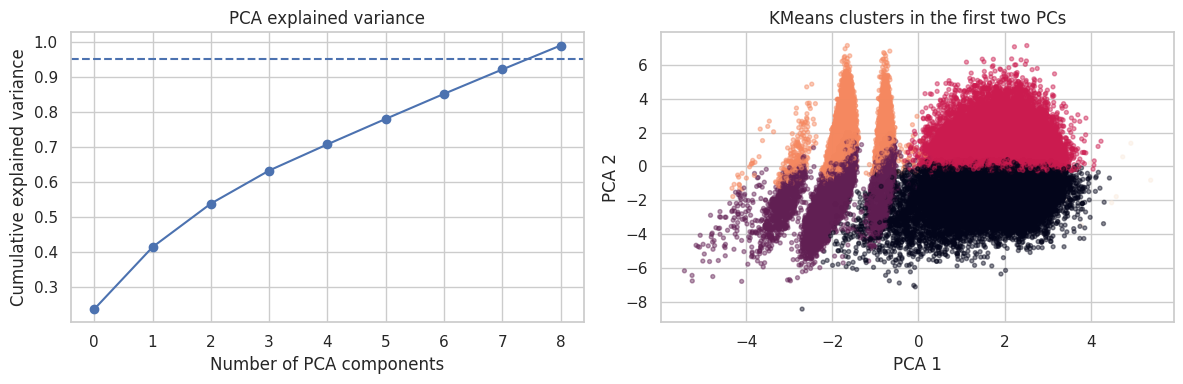

,feature set,validation ROC-AUC
0,Engineered features only,0.889575
1,Engineered + PCA + KMeans,0.889070


Keep PCA/KMeans as exploratory analysis unless the gain is repeatable across seeds/folds.


In [15]:
UNSUP_NUM_COLS = NUM_COLS
unsup_imputer = SimpleImputer(strategy="median")
pca_scaler = StandardScaler()
X_train_unsup_imputed = unsup_imputer.fit_transform(X_train_raw[UNSUP_NUM_COLS])
X_train_unsup_scaled = pca_scaler.fit_transform(X_train_unsup_imputed)
pca = PCA(n_components=0.95, random_state=SEED)
X_train_pcs = pca.fit_transform(X_train_unsup_scaled)
kmeans = KMeans(n_clusters=5, random_state=SEED, n_init=10)
kmeans.fit(X_train_unsup_scaled)


def add_pca_cluster_features(frame):
    imputed = unsup_imputer.transform(frame[UNSUP_NUM_COLS])
    scaled = pca_scaler.transform(imputed)
    pcs = pca.transform(scaled)
    result = frame.copy()
    for i in range(pcs.shape[1]):
        result[f"PCA_{i + 1}"] = pcs[:, i]
    result["KMeansCluster"] = kmeans.predict(scaled).astype(str)
    return result

X_train_pca = add_pca_cluster_features(X_train_raw)
X_val_pca = add_pca_cluster_features(X_val_raw)
X_test_pca = add_pca_cluster_features(X_test_raw)
X_extra_pca = add_pca_cluster_features(X_extra_raw) if X_extra_raw is not None else None
CAT_COLS_PCA = X_train_pca.select_dtypes(include=["object", "category"]).columns.tolist()

print("Number of PCA components retaining 95% variance:", pca.n_components_)
print("Cumulative explained variance:", round(pca.explained_variance_ratio_.sum(), 4))
print("Cluster sizes in training split:")
display(pd.Series(kmeans.labels_).value_counts().sort_index().rename("rows").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(np.cumsum(pca.explained_variance_ratio_), marker="o")
axes[0].axhline(0.95, linestyle="--")
axes[0].set_xlabel("Number of PCA components")
axes[0].set_ylabel("Cumulative explained variance")
axes[0].set_title("PCA explained variance")
axes[1].scatter(X_train_pcs[:, 0], X_train_pcs[:, 1], c=kmeans.labels_, s=8, alpha=0.45)
axes[1].set_xlabel("PCA 1")
axes[1].set_ylabel("PCA 2")
axes[1].set_title("KMeans clusters in the first two PCs")
plt.tight_layout()
plt.show()

# A controlled ablation: same CatBoost configuration, with vs. without PCA/cluster features.
pca_ablation_params = {
    "iterations": 600,
    "depth": 7,
    "learning_rate": 0.05,
    "l2_leaf_reg": 5.0,
}
X_cat_ablation_train, y_cat_ablation_train = combine_with_extra(X_train_raw, y_train)
X_cat_ablation_pca = X_train_pca.reset_index(drop=True)
y_cat_ablation_pca = y_train.reset_index(drop=True)
if X_extra_pca is not None:
    X_cat_ablation_pca = pd.concat([X_cat_ablation_pca, X_extra_pca.reset_index(drop=True)], ignore_index=True)
    y_cat_ablation_pca = pd.concat([y_cat_ablation_pca, y_extra.reset_index(drop=True)], ignore_index=True)

cat_no_pca = make_catboost(pca_ablation_params, CAT_COLS)
cat_no_pca.fit(X_cat_ablation_train, y_cat_ablation_train)
cat_no_pca_auc = roc_auc_score(y_val, cat_no_pca.predict_proba(X_val_raw)[:, 1])

cat_with_pca = make_catboost(pca_ablation_params, CAT_COLS_PCA)
cat_with_pca.fit(X_cat_ablation_pca, y_cat_ablation_pca)
cat_with_pca_auc = roc_auc_score(y_val, cat_with_pca.predict_proba(X_val_pca)[:, 1])

pca_ablation_results = pd.DataFrame([
    {"feature set": "Engineered features only", "validation ROC-AUC": cat_no_pca_auc},
    {"feature set": "Engineered + PCA + KMeans", "validation ROC-AUC": cat_with_pca_auc},
])
display(pca_ablation_results.style.format({"validation ROC-AUC": "{:.6f}"}))
print("Keep PCA/KMeans as exploratory analysis unless the gain is repeatable across seeds/folds.")

## 7. Fit the tuned models and compare validation metrics

The tuned XGBoost and LightGBM models use one-hot encoded categorical values inside their pipelines. CatBoost uses the raw categorical columns natively. When the optional original dataset is enabled, those rows are appended to the model-fitting partition only; the validation labels always come from the held-out competition rows.

,model,ROC-AUC,accuracy@0.50,precision@0.50,recall@0.50,F1@0.50,log_loss
0,XGBoost tuned,0.89019,0.86518,0.74459,0.55226,0.63417,0.31887
1,LightGBM tuned,0.88976,0.86512,0.74525,0.55083,0.63346,0.31943
2,CatBoost tuned,0.88881,0.86454,0.74965,0.54023,0.62794,0.32044


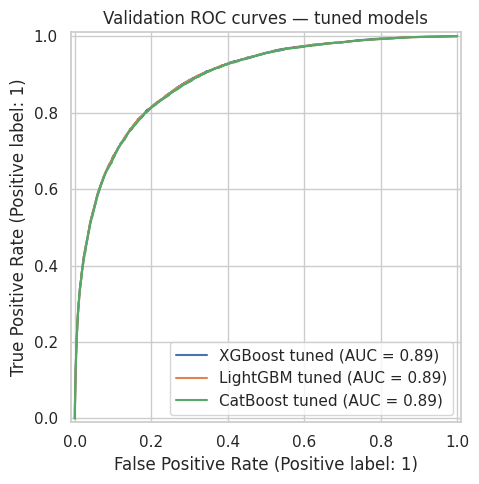

In [16]:
best_xgb_params = dict(study_xgb.best_params)
best_lgbm_params = dict(study_lgbm.best_params)
best_cat_params = dict(study_cat.best_params)

xgb_best = make_xgb_pipeline(best_xgb_params)
lgbm_best = make_lgbm_pipeline(best_lgbm_params)
cat_best = make_catboost(best_cat_params)

X_model_fit, y_model_fit = combine_with_extra(X_train_raw, y_train)
xgb_best.fit(X_model_fit, y_model_fit)
lgbm_best.fit(X_model_fit, y_model_fit)
cat_best.fit(X_model_fit, y_model_fit)

xgb_val_probs = xgb_best.predict_proba(X_val_raw)[:, 1]
lgbm_val_probs = lgbm_best.predict_proba(X_val_raw)[:, 1]
cat_val_probs = cat_best.predict_proba(X_val_raw)[:, 1]

model_rows = [
    metric_row("XGBoost tuned", y_val, xgb_val_probs),
    metric_row("LightGBM tuned", y_val, lgbm_val_probs),
    metric_row("CatBoost tuned", y_val, cat_val_probs),
]
model_results = pd.DataFrame(model_rows).sort_values("ROC-AUC", ascending=False)
display(model_results.style.format({c: "{:.5f}" for c in model_results.columns if c != "model"}))

fig, ax = plt.subplots(figsize=(8, 5))
for name, probs in [
    ("XGBoost tuned", xgb_val_probs),
    ("LightGBM tuned", lgbm_val_probs),
    ("CatBoost tuned", cat_val_probs),
]:
    RocCurveDisplay.from_predictions(y_val, probs, name=name, ax=ax)
ax.set_title("Validation ROC curves — tuned models")
plt.tight_layout()
plt.show()

## 8. Out-of-fold stacking

We use manual out-of-fold (OOF) stacking rather than a single in-sample blend. Each training row receives base-model predictions from models that did not train on that row; a logistic-regression meta-model learns how to combine those probabilities. Manual stacking also lets CatBoost keep native categorical handling while XGBoost and LightGBM use one-hot pipelines.

Completed stack fold 1/5
Completed stack fold 2/5
Completed stack fold 3/5
Completed stack fold 4/5
Completed stack fold 5/5
Validation model comparison (sorted by ROC-AUC):


,model,ROC-AUC,accuracy@0.50,precision@0.50,recall@0.50,F1@0.50,log_loss
0,XGBoost tuned,0.89019,0.86518,0.74459,0.55226,0.63417,0.31887
1,OOF stacked ensemble,0.88989,0.86542,0.74834,0.54840,0.63295,0.32904
2,LightGBM tuned,0.88976,0.86512,0.74525,0.55083,0.63346,0.31943
3,XGBoost baseline,0.88945,0.86527,0.74371,0.55427,0.63516,0.31952
4,CatBoost tuned,0.88881,0.86454,0.74965,0.54023,0.62794,0.32044
5,Logistic regression,0.87701,0.86200,0.74305,0.53164,0.61981,0.33335
6,Dummy / prior,0.50000,0.78841,0.00000,0.00000,0.00000,0.51606


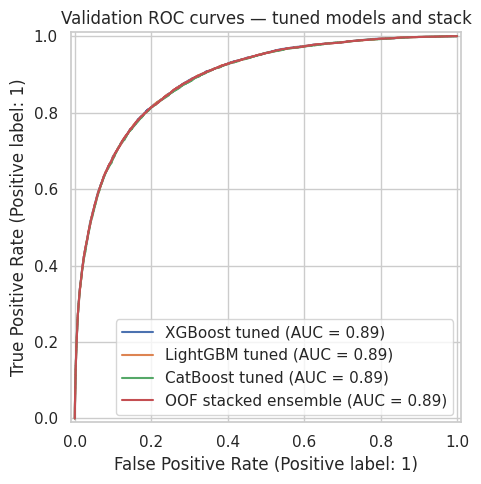

In [17]:
def fit_oof_stack(X_fit, y_fit, X_predict, extra_X=None, extra_y=None, n_splits=5, verbose=True):
    """Fit OOF meta-features, then refit base models on all supplied training rows."""
    X_fit = X_fit.reset_index(drop=True)
    y_fit = pd.Series(y_fit).reset_index(drop=True)
    stack_cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    oof = np.zeros((len(X_fit), 3), dtype=float)

    for fold, (train_idx, valid_idx) in enumerate(stack_cv.split(X_fit, y_fit), start=1):
        X_fold = X_fit.iloc[train_idx].reset_index(drop=True)
        y_fold = y_fit.iloc[train_idx].reset_index(drop=True)
        X_fold, y_fold = combine_with_extra(X_fold, y_fold, extra_X, extra_y)
        X_fold_valid = X_fit.iloc[valid_idx]

        fold_xgb = make_xgb_pipeline(best_xgb_params)
        fold_lgbm = make_lgbm_pipeline(best_lgbm_params)
        fold_cat = make_catboost(best_cat_params)

        fold_xgb.fit(X_fold, y_fold)
        fold_lgbm.fit(X_fold, y_fold)
        fold_cat.fit(X_fold, y_fold)

        oof[valid_idx, 0] = fold_xgb.predict_proba(X_fold_valid)[:, 1]
        oof[valid_idx, 1] = fold_lgbm.predict_proba(X_fold_valid)[:, 1]
        oof[valid_idx, 2] = fold_cat.predict_proba(X_fold_valid)[:, 1]
        if verbose:
            print(f"Completed stack fold {fold}/{n_splits}")

    meta_model = LogisticRegression(max_iter=2000, random_state=SEED)
    meta_model.fit(oof, y_fit)

    X_full, y_full = combine_with_extra(X_fit, y_fit, extra_X, extra_y)
    full_base_models = [
        make_xgb_pipeline(best_xgb_params),
        make_lgbm_pipeline(best_lgbm_params),
        make_catboost(best_cat_params),
    ]
    for base_model in full_base_models:
        base_model.fit(X_full, y_full)

    predict_base_probs = np.column_stack([
        full_base_models[0].predict_proba(X_predict)[:, 1],
        full_base_models[1].predict_proba(X_predict)[:, 1],
        full_base_models[2].predict_proba(X_predict)[:, 1],
    ])
    stack_probs = meta_model.predict_proba(predict_base_probs)[:, 1]
    return stack_probs, meta_model, full_base_models, oof

stack_val_probs, stack_meta_model, stack_base_models, stack_oof_train = fit_oof_stack(
    X_train_raw,
    y_train,
    X_val_raw,
    extra_X=X_extra_raw,
    extra_y=y_extra,
    n_splits=STACK_FOLDS,
)
stack_metrics = metric_row("OOF stacked ensemble", y_val, stack_val_probs)

all_validation_results = pd.concat([
    baseline_results,
    model_results,
    pd.DataFrame([stack_metrics]),
], ignore_index=True).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
print("Validation model comparison (sorted by ROC-AUC):")
display(all_validation_results.style.format({c: "{:.5f}" for c in all_validation_results.columns if c != "model"}))

fig, ax = plt.subplots(figsize=(8, 5))
for name, probs in [
    ("XGBoost tuned", xgb_val_probs),
    ("LightGBM tuned", lgbm_val_probs),
    ("CatBoost tuned", cat_val_probs),
    ("OOF stacked ensemble", stack_val_probs),
]:
    RocCurveDisplay.from_predictions(y_val, probs, name=name, ax=ax)
ax.set_title("Validation ROC curves — tuned models and stack")
plt.tight_layout()
plt.show()

## 9. Feature importance and SHAP

Feature importance gives a quick global ranking; SHAP estimates how each input feature contributes to the model output. Here we interpret the tuned LightGBM model, which uses the one-hot encoded feature matrix. SHAP runs on a sample to keep memory/runtime manageable. These are model explanations, not causal claims about why customers churn.

,feature,importance
25,num__CreditScore,792
26,num__Age,726
28,num__Balance,673
32,num__EstimatedSalary,672
37,num__AgeTimesProducts,626
36,num__TenureAgeRatio,489
38,num__CreditScorePerAge,441
35,num__BalanceCreditScoreRatio,424
31,num__IsActiveMember,415
33,num__BalanceSalaryRatio,357


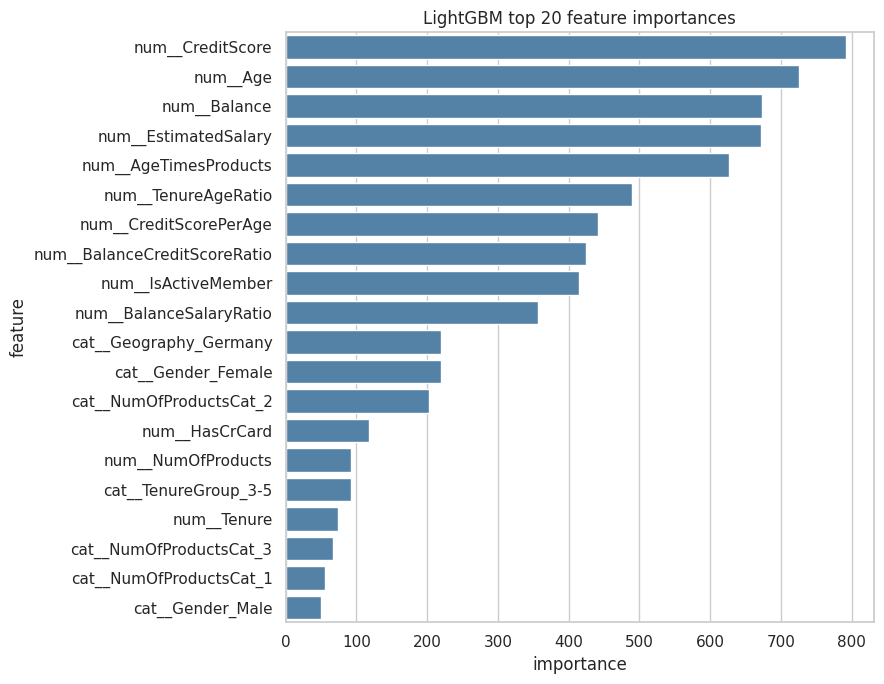

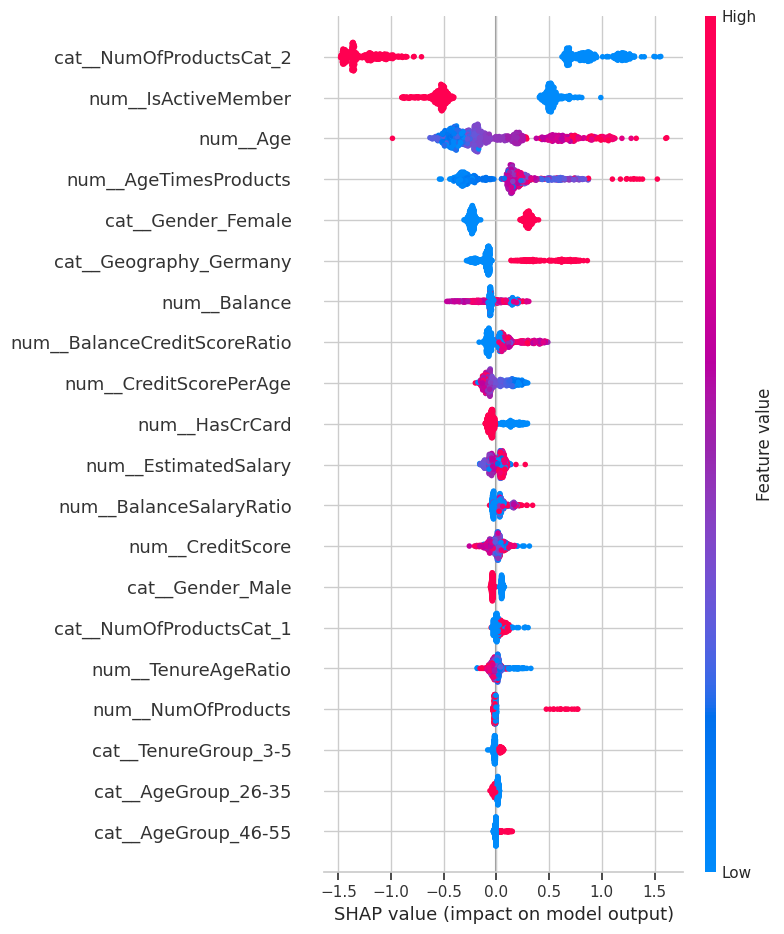

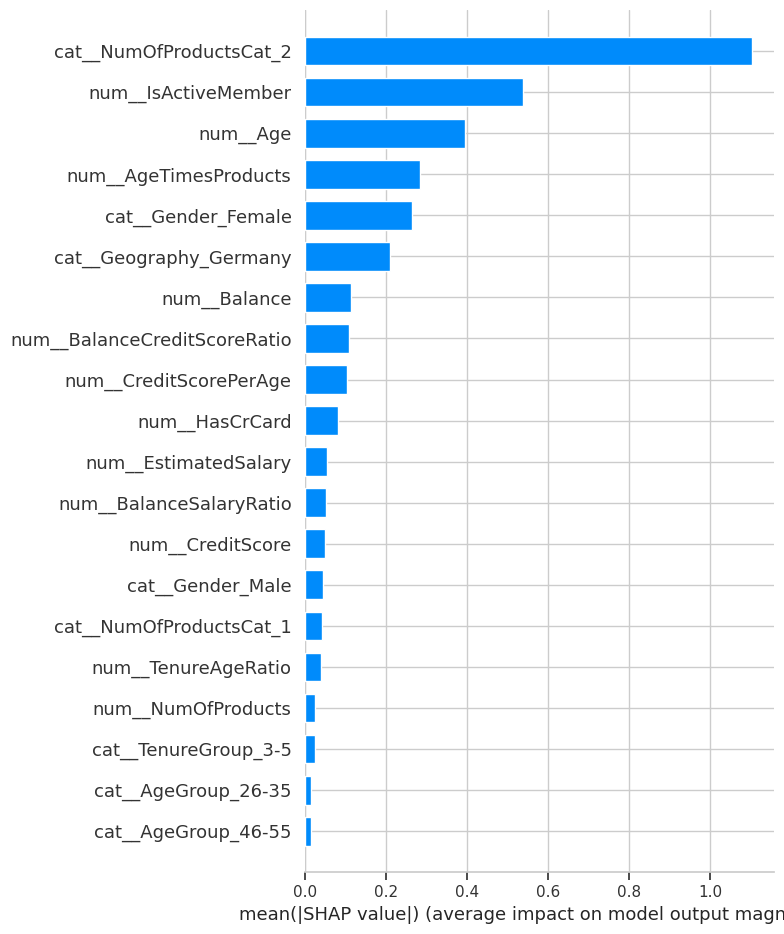

In [18]:
# LightGBM gain/split importance with human-readable one-hot feature names.
lgbm_preprocessor = lgbm_best.named_steps["preprocessor"]
lgbm_core = lgbm_best.named_steps["model"]
feature_names = lgbm_preprocessor.get_feature_names_out()
importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": lgbm_core.feature_importances_,
}).sort_values("importance", ascending=False).head(20)

display(importance_df)
plt.figure(figsize=(9, 7))
sns.barplot(data=importance_df, x="importance", y="feature", color="steelblue")
plt.title("LightGBM top 20 feature importances")
plt.tight_layout()
plt.show()

# SHAP for a manageable validation sample. A sample of 500-1000 is usually enough for a useful overview.
SHAP_SAMPLE_SIZE = min(800, len(X_val_raw))
X_shap_raw = X_val_raw.sample(SHAP_SAMPLE_SIZE, random_state=SEED)
X_shap_encoded_array = lgbm_preprocessor.transform(X_shap_raw)
X_shap_encoded = pd.DataFrame(
    X_shap_encoded_array,
    columns=feature_names,
    index=X_shap_raw.index,
)

explainer = shap.TreeExplainer(lgbm_core)
shap_values = explainer.shap_values(X_shap_encoded)
if isinstance(shap_values, list):
    shap_values_plot = shap_values[1] if len(shap_values) > 1 else shap_values[0]
else:
    shap_values_plot = np.asarray(shap_values)
    if shap_values_plot.ndim == 3:
        shap_values_plot = shap_values_plot[:, :, 1]

shap.summary_plot(shap_values_plot, X_shap_encoded, max_display=20, show=False)
plt.tight_layout()
plt.show()

shap.summary_plot(shap_values_plot, X_shap_encoded, plot_type="bar", max_display=20, show=False)
plt.tight_layout()
plt.show()